# Part A Question 3: POS Taggers and Syntactic Analysis

This notebook demonstrates POS tagging using the NLTK POS tagger, TextBlob POS tagger, and a regular-expression tagger. It also builds a parse tree for `Data_2.txt`.

In [1]:
import matplotlib.pyplot as plt
import string
from pathlib import Path
from pprint import pprint
from typing import Any, cast

from nltk import CFG, ChartParser, RegexpTagger, pos_tag
from nltk.tokenize import word_tokenize
from textblob import TextBlob

In [2]:
DATA_PATH = Path('data/Data_2.txt')
if not DATA_PATH.exists():
    DATA_PATH = Path('../data/Data_2.txt')


def load_text(path: Path) -> str:
    """Read a UTF-8 text file and normalize whitespace."""

    return ' '.join(path.read_text(encoding='utf-8').split())


text = load_text(DATA_PATH)
text

'The big black dog barked at the white cat and chased away.'

## 1. Tokenization

In [3]:
def word_tokens(text: str) -> list[str]:
    """Return NLTK word tokens, including punctuation."""

    return word_tokenize(text)


tokens = word_tokens(text)
pprint(tokens)

['The',
 'big',
 'black',
 'dog',
 'barked',
 'at',
 'the',
 'white',
 'cat',
 'and',
 'chased',
 'away',
 '.']


## 2. NLTK POS Tagger

In [4]:
nltk_tags = pos_tag(tokens)
print('NLTK POS tags:')
pprint(nltk_tags)

NLTK POS tags:
[('The', 'DT'),
 ('big', 'JJ'),
 ('black', 'JJ'),
 ('dog', 'NN'),
 ('barked', 'VBD'),
 ('at', 'IN'),
 ('the', 'DT'),
 ('white', 'JJ'),
 ('cat', 'NN'),
 ('and', 'CC'),
 ('chased', 'VBD'),
 ('away', 'RB'),
 ('.', '.')]


## 3. TextBlob POS Tagger

In [5]:
textblob_tags = [(str(word), str(tag)) for word, tag in cast(list[tuple[Any, Any]], TextBlob(text).tags)]
print('TextBlob POS tags:')
pprint(textblob_tags)

TextBlob POS tags:
[('The', 'DT'),
 ('big', 'JJ'),
 ('black', 'JJ'),
 ('dog', 'NN'),
 ('barked', 'VBD'),
 ('at', 'IN'),
 ('the', 'DT'),
 ('white', 'JJ'),
 ('cat', 'NN'),
 ('and', 'CC'),
 ('chased', 'VBD'),
 ('away', 'RB')]


## 4. Regular Expression Tagger

In [6]:
regex_tagger = RegexpTagger(
    [
        (r'^[^\w\s]$', '.'),
        (r'(?i)^(the|a|an)$', 'DT'),
        (r'(?i)^(and|or|but)$', 'CC'),
        (r'(?i)^(at|in|on|by|for|from|to|with)$', 'IN'),
        (r'(?i)^.*ed$', 'VBD'),
        (r'(?i)^(big|black|white)$', 'JJ'),
        (r'(?i)^away$', 'RB'),
        (r'(?i)^.*$', 'NN'),
    ]
)
regex_tags = regex_tagger.tag(tokens)
print('Regex-based POS tags:')
pprint(regex_tags)

Regex-based POS tags:
[('The', 'DT'),
 ('big', 'JJ'),
 ('black', 'JJ'),
 ('dog', 'NN'),
 ('barked', 'VBD'),
 ('at', 'IN'),
 ('the', 'DT'),
 ('white', 'JJ'),
 ('cat', 'NN'),
 ('and', 'CC'),
 ('chased', 'VBD'),
 ('away', 'RB'),
 ('.', '.')]


## 5. Parse Tree

In [7]:
grammar = CFG.fromstring(
    """
    S -> Clause Punct
    Clause -> NP VP
    NP -> Det AdjSeq N
    AdjSeq -> Adj Adj | Adj
    VP -> VP CC VP | VBD PP | VBD Adv
    PP -> P NP
    Det -> 'The' | 'the'
    Adj -> 'big' | 'black' | 'white'
    N -> 'dog' | 'cat'
    VBD -> 'barked' | 'chased'
    P -> 'at'
    CC -> 'and'
    Adv -> 'away'
    Punct -> '.'
    """
)

parser = ChartParser(grammar)
parse_trees = list(parser.parse(tokens))

for tree in parse_trees:
    print(tree.pformat(margin=100))

(S
  (Clause
    (NP (Det The) (AdjSeq (Adj big) (Adj black)) (N dog))
    (VP
      (VP (VBD barked) (PP (P at) (NP (Det the) (AdjSeq (Adj white)) (N cat))))
      (CC and)
      (VP (VBD chased) (Adv away))))
  (Punct .))


## 6. Visual Parse Tree

C:\Users\nicho\AppData\Local\Temp\ipykernel_6332\2570943059.py:64: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


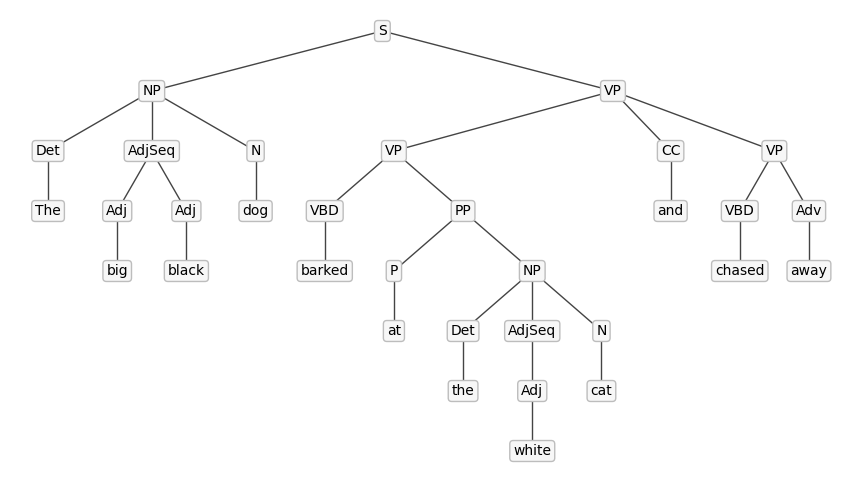

WindowsPath('../outputs/question_3_parse_tree.png')

In [8]:
def leaf_count(tree) -> int:
    """Count leaves under an NLTK tree or string leaf."""

    if isinstance(tree, str):
        return 1
    return sum(leaf_count(child) for child in tree)


def assign_positions(tree, depth=0, x_start=0, positions=None):
    """Assign x/y positions to each node for plotting."""

    if positions is None:
        positions = {}

    if isinstance(tree, str):
        node_id = id(tree) + x_start
        positions[node_id] = {'label': tree, 'x': x_start + 0.5, 'y': -depth, 'children': []}
        return node_id, x_start + 1, positions

    child_ids = []
    current_x = x_start
    for child in tree:
        child_id, current_x, positions = assign_positions(child, depth + 1, current_x, positions)
        child_ids.append(child_id)

    node_id = id(tree)
    child_x_values = [positions[child_id]['x'] for child_id in child_ids]
    positions[node_id] = {
        'label': tree.label(),
        'x': sum(child_x_values) / len(child_x_values),
        'y': -depth,
        'children': child_ids,
    }
    return node_id, current_x, positions


def draw_parse_tree(tree, output_path: Path) -> Path:
    """Draw and save a visual parse tree."""

    root_id, _, positions = assign_positions(tree)
    width = max(10, leaf_count(tree) * 0.9)
    height = 6

    fig, ax = plt.subplots(figsize=(width, height))
    ax.axis('off')

    for node_id, node in positions.items():
        for child_id in node['children']:
            child = positions[child_id]
            ax.plot([node['x'], child['x']], [node['y'], child['y']], color='#444444', linewidth=1)

    for node in positions.values():
        ax.text(
            node['x'],
            node['y'],
            node['label'],
            ha='center',
            va='center',
            fontsize=10,
            bbox={'boxstyle': 'round,pad=0.25', 'facecolor': '#F7F7F7', 'edgecolor': '#BDBDBD'},
        )

    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(output_path, dpi=200, bbox_inches='tight')
    plt.show()
    return output_path


OUTPUT_PATH = Path('outputs/question_3_parse_tree.png')
if not Path('data/Data_2.txt').exists():
    OUTPUT_PATH = Path('../outputs/question_3_parse_tree.png')

parse_tree_image = draw_parse_tree(parse_trees[0], OUTPUT_PATH)
parse_tree_image
